In [1]:
'''Compare performance metrics of various baseline models(Logistic Regression, Decision Trees, KNN, SVM) 
on training and validation data to establish benchmark performance standards.'''

'Compare performance metrics of various baseline models(Logistic Regression, Decision Trees, KNN, SVM) \non training and validation data to establish benchmark performance standards.'

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Adm.csv")
display(df.head())
print("\ncolumn information:")
df.info()

# check missing values in each column
print("\nmissing values:")
print(df.isnull().sum())

# check for duplicate records
print("\nduplicate records:", df.duplicated().sum())

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.92,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.76,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.72,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.80,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.65,2022-01-08 09:00:00,Jamia Millia Islamia,North



column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Serial No.            1000 non-null   int64  
 1   GRE Score             1000 non-null   int64  
 2   TOEFL Score           1000 non-null   int64  
 3   University Rating     1000 non-null   int64  
 4   SOP                   1000 non-null   float64
 5   LOR                   1000 non-null   float64
 6   CGPA                  1000 non-null   float64
 7   Research              1000 non-null   int64  
 8   Chance of Admit       1000 non-null   float64
 9   Application_DateTime  1000 non-null   object 
 10  University_Name       1000 non-null   object 
 11  region                1000 non-null   object 
dtypes: float64(4), int64(5), object(3)
memory usage: 93.9+ KB

missing values:
Serial No.              0
GRE Score               0
TOEFL Score             0
U

In [5]:
#create admission classes for prepare the classification target
# remove rows where the target value is missing
df = df.dropna(subset=["Chance of Admit"]).copy()

# convert admission chances into two classes
# 1 means likely admit and 0 means less likely admit
df["Admission_Status"] = (
    df["Chance of Admit"] >= 0.70
).astype(int)

# display the number of applicants in each class
print("admission class distribution:")
print(
    df["Admission_Status"]
    .value_counts()
    .rename(index={0: "Less Likely Admit", 1: "Likely Admit"})
)

# display the percentage of each class
print("\nclass percentage:")
print(
    (df["Admission_Status"].value_counts(normalize=True) * 100)
    .round(2)
)

admission class distribution:
Admission_Status
Likely Admit         594
Less Likely Admit    406
Name: count, dtype: int64

class percentage:
Admission_Status
1    59.4
0    40.6
Name: proportion, dtype: float64


In [6]:
# feature selection 
# select useful applicant features
features = [
    "GRE Score",
    "TOEFL Score",
    "University Rating",
    "SOP",
    "LOR",
    "CGPA",
    "Research",
    "University_Name",
    "region"
]

# separate the input features and target
X = df[features]
y = df["Admission_Status"]

# identify numerical features
numeric_features = [
    "GRE Score",
    "TOEFL Score",
    "University Rating",
    "SOP",
    "LOR",
    "CGPA",
    "Research"
]

# identify categorical features
categorical_features = [
    "University_Name",
    "region"
]

print("input data shape:", X.shape)
print("target data shape:", y.shape)

input data shape: (1000, 9)
target data shape: (1000,)


In [ ]:
# split the data into training and validation sets
from sklearn.model_selection import train_test_split
# split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# display the number of records in each set
print("training records:", X_train.shape[0])
print("validation records:", X_val.shape[0])

# check class proportions in both sets
print("\ntraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nvalidation class distribution:")
print(y_val.value_counts(normalize=True).round(3))

training records: 800
validation records: 200

training class distribution:
Admission_Status
1    0.594
0    0.406
Name: proportion, dtype: float64

validation class distribution:
Admission_Status
1    0.595
0    0.405
Name: proportion, dtype: float64


In [9]:
# scale numerical columns and encode text-based columns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
# create the four baseline classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    )
}

# connect preprocessing with each model
pipelines = {}

for name, model in models.items():

    # create a complete preprocessing and classification pipeline
    pipelines[name] = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

print("all four baseline models are ready")

all four baseline models are ready


In [ ]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,
    classification_report,
    confusion_matrix,
    )

# store the evaluation results for each model
results = []

# train and evaluate each classifier
for name, pipeline in pipelines.items():

    print(f"\ntraining {name}...")

    # train the model using only the training data
    pipeline.fit(X_train, y_train)

    # predict the training and validation classes
    train_pred = pipeline.predict(X_train)
    val_pred = pipeline.predict(X_val)

    # calculate training and validation metrics
    results.append({
        "Model": name,

        "Training Accuracy": accuracy_score(
            y_train, train_pred
        ),
        "Validation Accuracy": accuracy_score(
            y_val, val_pred
        ),

        "Training Precision": precision_score(
            y_train, train_pred, zero_division=0
        ),
        "Validation Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),

        "Training Recall": recall_score(
            y_train, train_pred, zero_division=0
        ),
        "Validation Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),

        "Training F1": f1_score(
            y_train, train_pred, zero_division=0
        ),
        "Validation F1": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

    print("training completed")

# convert the results into a dataframe
results_df = pd.DataFrame(results)

# display the complete model comparison
display(
    results_df
    .round(4)
    .sort_values("Validation F1", ascending=False)
    .reset_index(drop=True)
)


training Logistic Regression...
training completed

training Decision Tree...
training completed

training KNN...
training completed

training SVM...
training completed


,Model,Training Accuracy,Validation Accuracy,Training Precision,Validation Precision,Training Recall,Validation Recall,Training F1,Validation F1
0,SVM,0.7788,0.660,0.7633,0.6759,0.9095,0.8235,0.8300,0.7424
1,Logistic Regression,0.6862,0.665,0.7066,0.6970,0.8063,0.7731,0.7532,0.7331
2,Decision Tree,0.7562,0.630,0.7397,0.6531,0.9095,0.8067,0.8159,0.7218
3,KNN,0.7338,0.650,0.7589,0.6992,0.8084,0.7227,0.7829,0.7107


In [12]:
# calculate the difference between training and validation scores
results_df["Accuracy Gap"] = (
    results_df["Training Accuracy"]
    - results_df["Validation Accuracy"]
)

results_df["F1 Gap"] = (
    results_df["Training F1"]
    - results_df["Validation F1"]
)

# display the score differences
display(
    results_df[
        [
            "Model",
            "Training Accuracy",
            "Validation Accuracy",
            "Accuracy Gap",
            "Training F1",
            "Validation F1",
            "F1 Gap"
        ]
    ]
    .round(4)
    .sort_values("Validation F1", ascending=False)
    .reset_index(drop=True)
)

,Model,Training Accuracy,Validation Accuracy,Accuracy Gap,Training F1,Validation F1,F1 Gap
0,SVM,0.7788,0.660,0.1188,0.8300,0.7424,0.0875
1,Logistic Regression,0.6862,0.665,0.0212,0.7532,0.7331,0.0201
2,Decision Tree,0.7562,0.630,0.1262,0.8159,0.7218,0.0941
3,KNN,0.7338,0.650,0.0837,0.7829,0.7107,0.0721


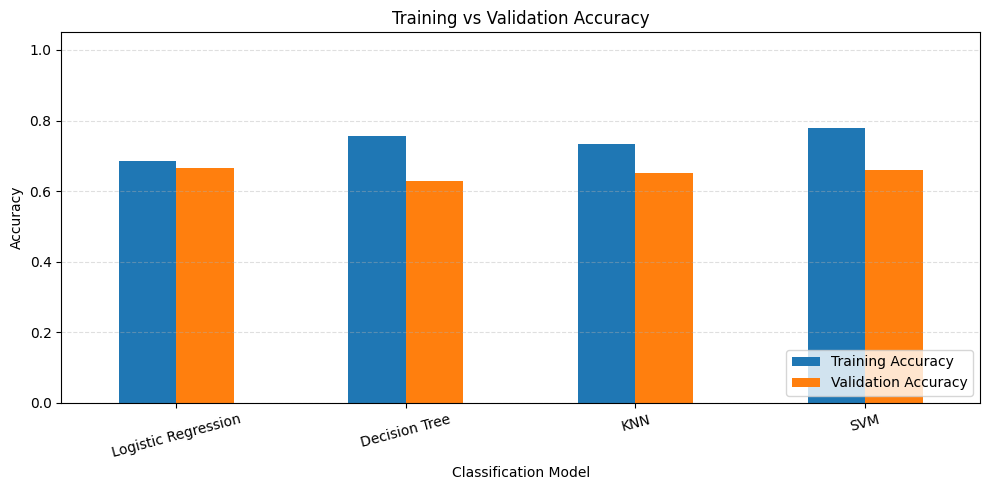

In [13]:
# prepare accuracy values for the chart
accuracy_comparison = results_df.set_index("Model")[
    ["Training Accuracy", "Validation Accuracy"]
]

# plot training and validation accuracy side by side
accuracy_comparison.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1.05),
    rot=15
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Classification Model")
plt.ylabel("Accuracy")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

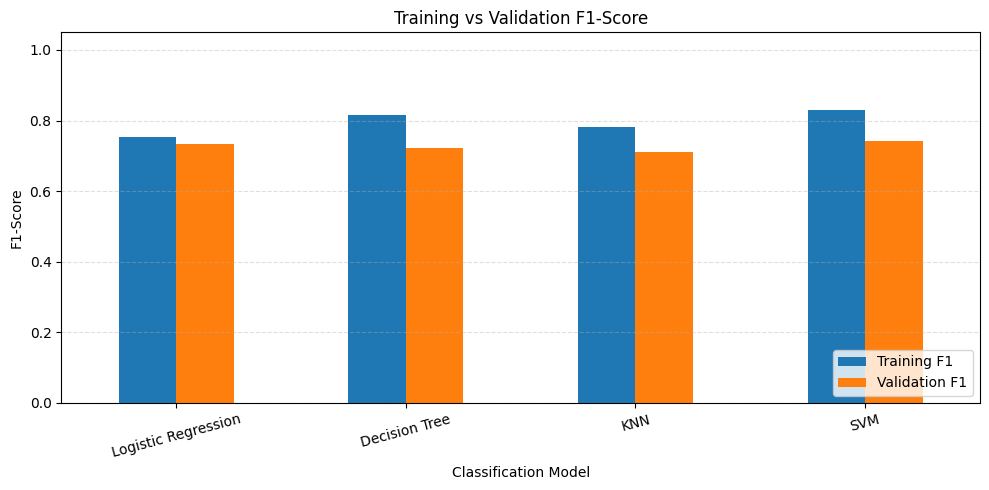

In [14]:
# prepare f1-score values for the chart
f1_comparison = results_df.set_index("Model")[
    ["Training F1", "Validation F1"]
]

# plot f1-scores to compare classification balance
f1_comparison.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1.05),
    rot=15
)

plt.title("Training vs Validation F1-Score")
plt.xlabel("Classification Model")
plt.ylabel("F1-Score")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

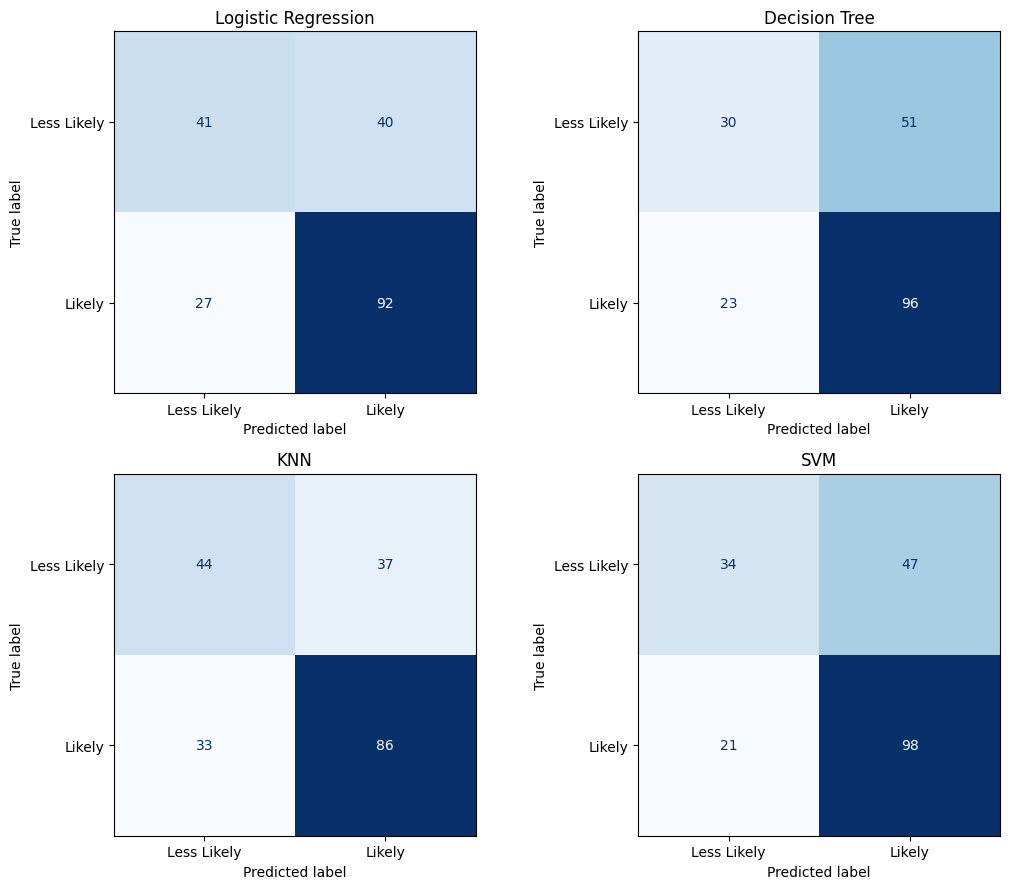

In [16]:
# create one confusion matrix for each trained model
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

for ax, (name, pipeline) in zip(axes, pipelines.items()):

    # predict the validation records
    val_pred = pipeline.predict(X_val)

    # calculate the actual and predicted class counts
    cm = confusion_matrix(
        y_val,
        val_pred,
        labels=[0, 1]
    )

    # display the confusion matrix
    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Less Likely", "Likely"]
    )

    display_matrix.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [17]:
# print detailed validation results for every model

for name, pipeline in pipelines.items():

    # predict the validation classes
    val_pred = pipeline.predict(X_val)

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    # display precision, recall, f1-score and class support
    print(
        classification_report(
            y_val,
            val_pred,
            labels=[0, 1],
            target_names=[
                "Less Likely Admit",
                "Likely Admit"
            ],
            zero_division=0
        )
    )


Logistic Regression
                   precision    recall  f1-score   support

Less Likely Admit       0.60      0.51      0.55        81
     Likely Admit       0.70      0.77      0.73       119

         accuracy                           0.67       200
        macro avg       0.65      0.64      0.64       200
     weighted avg       0.66      0.67      0.66       200


Decision Tree
                   precision    recall  f1-score   support

Less Likely Admit       0.57      0.37      0.45        81
     Likely Admit       0.65      0.81      0.72       119

         accuracy                           0.63       200
        macro avg       0.61      0.59      0.58       200
     weighted avg       0.62      0.63      0.61       200


KNN
                   precision    recall  f1-score   support

Less Likely Admit       0.57      0.54      0.56        81
     Likely Admit       0.70      0.72      0.71       119

         accuracy                           0.65       200
       

In [18]:
# rank models using validation f1-score
ranked_models = results_df.sort_values(
    by="Validation F1",
    ascending=False
).reset_index(drop=True)

# display the model ranking
print("baseline model ranking:")
display(
    ranked_models[
        [
            "Model",
            "Validation Accuracy",
            "Validation Precision",
            "Validation Recall",
            "Validation F1",
            "F1 Gap"
        ]
    ].round(4)
)

# select the model with the highest validation f1-score
best_model_name = ranked_models.loc[0, "Model"]
best_f1 = ranked_models.loc[0, "Validation F1"]
best_accuracy = ranked_models.loc[0, "Validation Accuracy"]

print("\nbest baseline model:", best_model_name)
print("validation accuracy:", round(best_accuracy, 4))
print("validation f1-score:", round(best_f1, 4))

# show the performance standards used in this practical
print("\nbenchmark interpretation:")
print("accuracy, precision, recall and f1-score range from 0 to 1.")
print("higher validation scores are generally better.")
print("a large positive f1 gap may indicate overfitting.")
print("consider class balance and confusion matrices before selecting a model.")

baseline model ranking:


,Model,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,F1 Gap
0,SVM,0.660,0.6759,0.8235,0.7424,0.0875
1,Logistic Regression,0.665,0.6970,0.7731,0.7331,0.0201
2,Decision Tree,0.630,0.6531,0.8067,0.7218,0.0941
3,KNN,0.650,0.6992,0.7227,0.7107,0.0721



best baseline model: SVM
validation accuracy: 0.66
validation f1-score: 0.7424

benchmark interpretation:
accuracy, precision, recall and f1-score range from 0 to 1.
higher validation scores are generally better.
a large positive f1 gap may indicate overfitting.
consider class balance and confusion matrices before selecting a model.
